In [73]:
import matplotlib.pyplot as plt
import numpy as np

from nonconvex_regression import (
    calculate_rmse,
    clean_data,
    gamma_kde,
    lp_irls,
    ols,
    outlier_data,
)

plt.style.use("seaborn-v0_8-whitegrid")

In [74]:
n = 1000
beta = np.array([1.0, 1.0])
epsilon = 1e-1
x_min, x_max = -2, 2
eps = 1e-3
maxiter = 500
tolerance = 1e-6

In [ ]:
p_range = np.linspace(0.1, 0.5, 25)
A_range = np.linspace(10, 100, 25)
lp_range = np.linspace(0.1, 0.9, 9)
seed = 1


method_names = ("Lp-IRLS", "OLS")
metric_names = ("Test RMSE", "Iterations")

# Now statistics has an extra dimension for lp_range
statistics = {
    method_name: {
        metric_name: np.zeros((len(lp_range), len(p_range), len(A_range)))
        for metric_name in metric_names
    }
    for method_name in method_names
}

# Generate each data set once so all methods see identical data and seeds.
seed_grid = (
    seed
    + 1
    + np.arange(len(p_range) * len(A_range)).reshape(len(p_range), len(A_range))
)
data_sweep = [[None for _ in A_range] for _ in p_range]
for p_index, p in enumerate(p_range):
    for A_index, A in enumerate(A_range):
        data_seed = seed_grid[p_index, A_index]
        clean_points = clean_data(n, beta, epsilon, x_min, x_max, data_seed)
        outlier_points = outlier_data(n, beta, epsilon, x_min, x_max, p, A, data_seed)
        data_sweep[p_index][A_index] = (clean_points, outlier_points)

# Lp-IRLS: sweep over lp_range (outside p/A loops so each lp uses the same data)
for lp_index, lp in enumerate(lp_range):
    for p_index in range(len(p_range)):
        for A_index in range(len(A_range)):
            clean_points, outlier_points = data_sweep[p_index][A_index]
            coefficients, iterations = lp_irls(
                outlier_points[:, 0:1],
                outlier_points[:, 1],
                lp,
                eps,
                maxiter=maxiter,
                tolerance=tolerance,
                return_iterations=True,
            )
            method_statistics = statistics["Lp-IRLS"]
            method_statistics["Test RMSE"][lp_index, p_index, A_index] = calculate_rmse(
                clean_points, coefficients
            )
            method_statistics["Iterations"][lp_index, p_index, A_index] = iterations

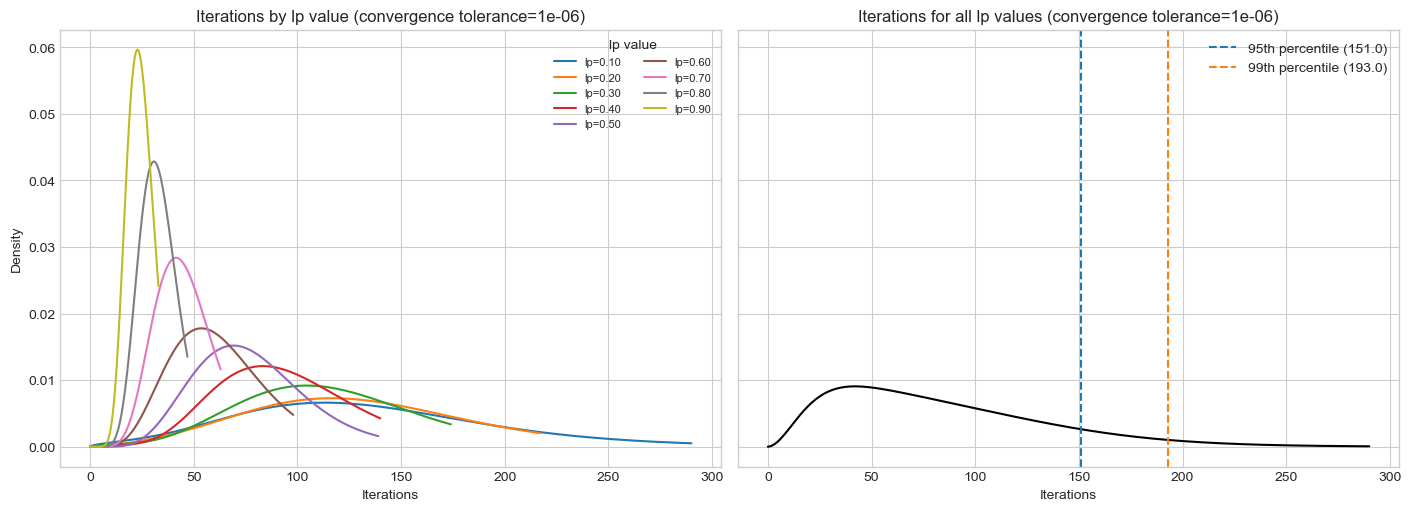

In [76]:
iteration_counts = statistics["Lp-IRLS"]["Iterations"]
fig, (ax_lp, ax_all) = plt.subplots(
    1, 2, figsize=(14, 5), sharey=True, constrained_layout=True
)

for lp_index, lp in enumerate(lp_range):
    x_grid, density = gamma_kde(iteration_counts[lp_index])
    ax_lp.plot(x_grid, density, label=f"lp={lp:.2f}")

ax_lp.set_title(f"Iterations by lp value (convergence tolerance={tolerance:.0e})")
ax_lp.set_xlabel("Iterations")
ax_lp.set_ylabel("Density")
ax_lp.legend(title="lp value", fontsize=8, ncol=2)

x_grid, density = gamma_kde(iteration_counts)
ax_all.plot(x_grid, density, color="black")
for percentile, value, color in zip(
    (95, 99),
    np.percentile(iteration_counts, [95, 99]),
    ("tab:blue", "tab:orange"),
    strict=False,
):
    ax_all.axvline(
        value,
        color=color,
        linestyle="--",
        label=f"{percentile}th percentile ({value:.1f})",
    )
ax_all.set_title(
    f"Iterations for all lp values (convergence tolerance={tolerance:.0e})"
)
ax_all.set_xlabel("Iterations")
ax_all.legend()

plt.show()

In [77]:
n = 1000
beta = np.array([1.0, 1.0])
epsilon = 1e-1
x_min, x_max = -2, 2
maxiter = 100
tolerance = 1e-6

In [78]:
p_range = np.linspace(0.1, 0.5, 25)
A_range = np.linspace(10, 100, 25)
lp_range = np.linspace(0.6, 0.9, 4)
eps_range = np.logspace(-1, -6, 6)
seed = 2

method_names = ("Lp-IRLS", "OLS")
metric_names = ("Test RMSE", "Iterations")

# Now statistics has an extra dimension for eps_range
statistics = {
    method_name: {
        metric_name: np.zeros(
            (len(lp_range), len(p_range), len(A_range), len(eps_range))
        )
        for metric_name in metric_names
    }
    for method_name in method_names
}

# Generate each data set once so all methods see identical data and seeds.
seed_grid = (
    seed
    + 1
    + np.arange(len(p_range) * len(A_range)).reshape(len(p_range), len(A_range))
)
data_sweep = [[None for _ in A_range] for _ in p_range]
for p_index, p in enumerate(p_range):
    for A_index, A in enumerate(A_range):
        data_seed = seed_grid[p_index, A_index]
        clean_points = clean_data(n, beta, epsilon, x_min, x_max, data_seed)
        outlier_points = outlier_data(n, beta, epsilon, x_min, x_max, p, A, data_seed)
        data_sweep[p_index][A_index] = (clean_points, outlier_points)

# Lp-IRLS: sweep over lp_range (outside p/A loops so each lp uses the same data)
for lp_index, lp in enumerate(lp_range):
    for eps_index, eps in enumerate(eps_range):
        for p_index in range(len(p_range)):
            for A_index in range(len(A_range)):
                clean_points, outlier_points = data_sweep[p_index][A_index]
                coefficients, iterations = lp_irls(
                    outlier_points[:, 0:1],
                    outlier_points[:, 1],
                    lp,
                    eps,
                    maxiter=maxiter,
                    tolerance=tolerance,
                    return_iterations=True,
                )
                method_statistics = statistics["Lp-IRLS"]
                method_statistics["Test RMSE"][
                    lp_index, p_index, A_index, eps_index
                ] = calculate_rmse(clean_points, coefficients)
                method_statistics["Iterations"][
                    lp_index, p_index, A_index, eps_index
                ] = iterations

# OLS is an eps-independent reference for test error; iteration counts do not apply.
for p_index in range(len(p_range)):
    for A_index in range(len(A_range)):
        clean_points, outlier_points = data_sweep[p_index][A_index]
        ols_coefficients = ols(outlier_points[:, 0:1], outlier_points[:, 1])
        ols_rmse = calculate_rmse(clean_points, ols_coefficients)
        statistics["OLS"]["Test RMSE"][:, p_index, A_index, :] = ols_rmse

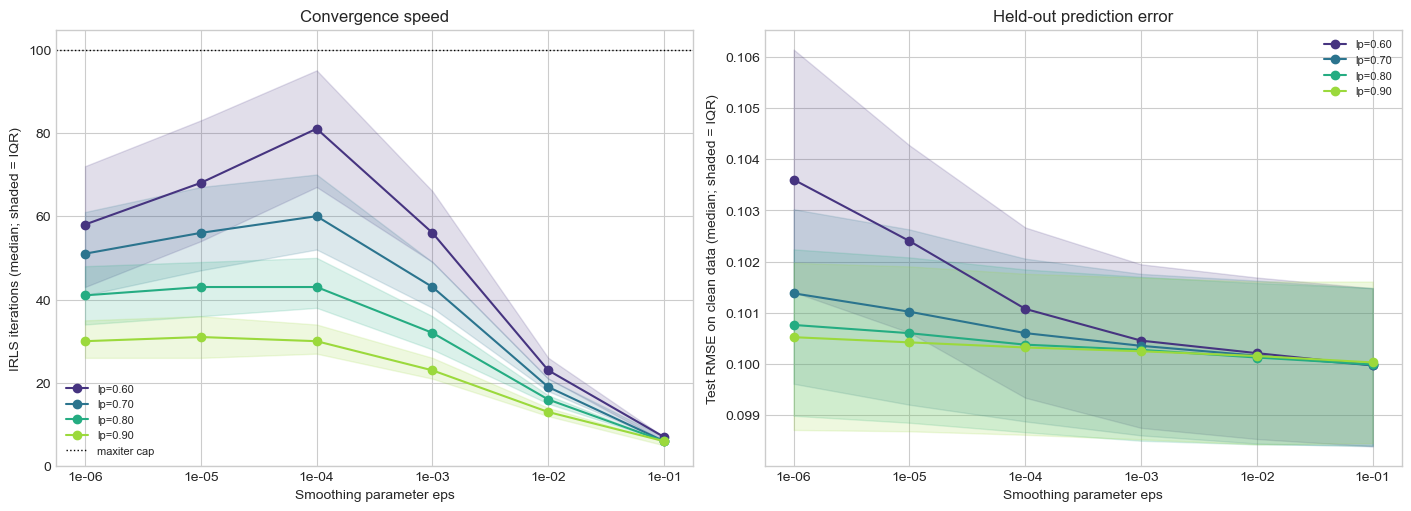

In [79]:
eps_order = np.argsort(eps_range)
eps_plot = eps_range[eps_order]
colors = plt.cm.viridis(np.linspace(0.15, 0.85, len(lp_range)))

fig, (ax_iterations, ax_error) = plt.subplots(
    1, 2, figsize=(14, 5), sharex=True, constrained_layout=True
)

for lp_index, (lp, color) in enumerate(zip(lp_range, colors, strict=False)):
    iteration_data = statistics["Lp-IRLS"]["Iterations"][lp_index]
    iteration_median = np.median(iteration_data, axis=(0, 1))[eps_order]
    iteration_q25, iteration_q75 = np.percentile(iteration_data, [25, 75], axis=(0, 1))
    ax_iterations.plot(
        eps_plot, iteration_median, marker="o", color=color, label=f"lp={lp:.2f}"
    )
    ax_iterations.fill_between(
        eps_plot,
        iteration_q25[eps_order],
        iteration_q75[eps_order],
        color=color,
        alpha=0.16,
    )

    error_data = statistics["Lp-IRLS"]["Test RMSE"][lp_index]
    error_median = np.median(error_data, axis=(0, 1))[eps_order]
    error_q25, error_q75 = np.percentile(error_data, [25, 75], axis=(0, 1))
    ax_error.plot(eps_plot, error_median, marker="o", color=color, label=f"lp={lp:.2f}")
    ax_error.fill_between(
        eps_plot,
        error_q25[eps_order],
        error_q75[eps_order],
        color=color,
        alpha=0.16,
    )

for ax in (ax_iterations, ax_error):
    ax.set_xscale("log")
    ax.set_xticks(eps_plot, [f"{value:.0e}" for value in eps_plot])
    ax.set_xlabel("Smoothing parameter eps")
    ax.legend(fontsize=8)

ax_iterations.axhline(
    maxiter, color="black", linestyle=":", linewidth=1, label="maxiter cap"
)
ax_iterations.set_title("Convergence speed")
ax_iterations.set_ylabel("IRLS iterations (median; shaded = IQR)")
ax_iterations.set_ylim(bottom=0)
ax_iterations.legend(fontsize=8)

ax_error.set_title("Held-out prediction error")
ax_error.set_ylabel("Test RMSE on clean data (median; shaded = IQR)")

plt.show()